# Unidad 4 — Entrenamiento y Comparación Experimental (PLN con Embeddings)

**Proyecto:** Sistema Neuro-Agéntico de Triaje PQRS Bancarias (Ruta 3)  
**Integrantes:** Andres Plazas y Jersson Montenegro  
**Dataset:** `mteb/banking77` (Hugging Face — tickets reales de soporte bancario agrupados en 5 colas operativas PQRS).

En este notebook realizamos:
1. Carga y mapeo de tickets bancarios reales en 5 categorías operativas.
2. Preprocesamiento y construcción del vocabulario **solo sobre entrenamiento** (evitando fuga de datos).
3. Comparación experimental entre **Modelo Base** (`Embedding + GlobalAveragePooling1D + Dense`) y **Modelo Mejorado** (`Embedding + SpatialDropout1D + Bidirectional LSTM + Dropout + EarlyStopping`).
4. Curvas reales de pérdida (`loss`) y precisión (`accuracy`) guardadas en `assets/`.
5. **Análisis de un fallo real (Error Analysis)** con identificador, valor real, predicción y probabilidad.
6. Exportación de pesos (`.keras`) y metadatos (`metadata_u4.json`) en `models/`.

In [ ]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from datasets import load_dataset
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from tensorflow.keras import callbacks, layers, models

# Reproducibilidad
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data'
MODELS_DIR = PROJECT_ROOT / 'models'
ASSETS_DIR = PROJECT_ROOT / 'assets'
for d in (DATA_DIR, MODELS_DIR, ASSETS_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'TensorFlow: {tf.__version__} | Keras: {tf.keras.__version__}')
print(f'Raíz del proyecto: {PROJECT_ROOT}')

D:\Documentos\GitHub\Taller-IA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.21.0 | Keras: 3.15.1
Raíz del proyecto: D:\Documentos\GitHub\Taller-IA


## 1. Carga del Dataset Público (`mteb/banking77`) y Agrupación en 5 Colas PQRS

In [2]:
ds = load_dataset('mteb/banking77')

MAPA_INTENCIONES_A_PQRS = {
    # 0. Fraude y Seguridad
    'compromised_card': 'Fraude y Seguridad',
    'card_payment_not_recognised': 'Fraude y Seguridad',
    'direct_debit_payment_not_recognised': 'Fraude y Seguridad',
    'cash_withdrawal_not_recognised': 'Fraude y Seguridad',
    'lost_or_stolen_card': 'Fraude y Seguridad',
    'lost_or_stolen_phone': 'Fraude y Seguridad',
    # 1. Transferencias y Pagos
    'failed_transfer': 'Transferencias y Pagos',
    'pending_transfer': 'Transferencias y Pagos',
    'transfer_not_received_by_recipient': 'Transferencias y Pagos',
    'declined_transfer': 'Transferencias y Pagos',
    'declined_card_payment': 'Transferencias y Pagos',
    'reverted_card_payment?': 'Transferencias y Pagos',
    # 2. Tarjetas y Activación
    'activate_my_card': 'Tarjetas y Activación',
    'card_arrival': 'Tarjetas y Activación',
    'card_delivery_estimate': 'Tarjetas y Activación',
    'card_not_working': 'Tarjetas y Activación',
    'pin_blocked': 'Tarjetas y Activación',
    'order_physical_card': 'Tarjetas y Activación',
    # 3. Comisiones y Reembolsos
    'card_payment_fee_charged': 'Comisiones y Reembolsos',
    'cash_withdrawal_charge': 'Comisiones y Reembolsos',
    'extra_charge_on_statement': 'Comisiones y Reembolsos',
    'refund_not_showing_up': 'Comisiones y Reembolsos',
    'request_refund': 'Comisiones y Reembolsos',
    'exchange_charge': 'Comisiones y Reembolsos',
    # 4. Cuenta y Verificación
    'verify_my_identity': 'Cuenta y Verificación',
    'unable_to_verify_identity': 'Cuenta y Verificación',
    'passcode_forgotten': 'Cuenta y Verificación',
    'edit_personal_details': 'Cuenta y Verificación',
    'terminate_account': 'Cuenta y Verificación',
    'why_verify_identity': 'Cuenta y Verificación',
}

CLASS_NAMES = [
    'Fraude y Seguridad',
    'Transferencias y Pagos',
    'Tarjetas y Activación',
    'Comisiones y Reembolsos',
    'Cuenta y Verificación',
]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}

def filtrar_split(split_ds, nombre_split):
    filas = []
    for idx, row in enumerate(split_ds):
        intent = row['label_text']
        if intent in MAPA_INTENCIONES_A_PQRS:
            cat = MAPA_INTENCIONES_A_PQRS[intent]
            filas.append({
                'orig_id': f'{nombre_split}_{idx}',
                'text': row['text'],
                'intent_original': intent,
                'categoria': cat,
                'label': CLASS_TO_IDX[cat],
                'split': nombre_split,
            })
    return pd.DataFrame(filas)

df_train = filtrar_split(ds['train'], 'train')
df_test = filtrar_split(ds['test'], 'test')

# Guardar copia ligera para reproducibilidad
pd.concat([df_train, df_test], ignore_index=True).to_csv(
    DATA_DIR / 'banking_pqrs_dataset.csv', index=False
)

print(f'Muestras entrenamiento: {len(df_train)} | Muestras prueba: {len(df_test)}')
print('\nDistribución por categoría (entrenamiento):')
print(df_train['categoria'].value_counts())
print('\nDistribución por categoría (prueba):')
print(df_test['categoria'].value_counts())

D:\Documentos\GitHub\Taller-IA\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Jerson\.cache\huggingface\hub\datasets--mteb--banking77. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


D:\Documentos\GitHub\Taller-IA\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Jerson\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)



Generating train split:   0%|          | 0/9993 [00:00<?, ? examples/s]


Generating train split:  10%|█         | 1000/9993 [00:00<00:04, 2196.25 examples/s]


Generating train split: 100%|██████████| 9993/9993 [00:00<00:00, 21612.40 examples/s]


Generating test split:   0%|          | 0/3076 [00:00<?, ? examples/s]


Generating test split: 100%|██████████| 3076/3076 [00:00<00:00, 139624.03 examples/s]

Muestras entrenamiento: 3949 | Muestras prueba: 1158

Distribución por categoría (entrenamiento):
categoria
Transferencias y Pagos     902
Comisiones y Reembolsos    820
Fraude y Seguridad         799
Tarjetas y Activación      769
Cuenta y Verificación      659
Name: count, dtype: int64

Distribución por categoría (prueba):
categoria
Tarjetas y Activación      240
Fraude y Seguridad         240
Cuenta y Verificación      240
Transferencias y Pagos     238
Comisiones y Reembolsos    200
Name: count, dtype: int64


## 2. Preprocesamiento y Tokenización (Sin Fuga de Datos)

Construimos el vocabulario `word_to_index` **exclusivamente con los textos de entrenamiento** para evitar cualquier fuga de información del conjunto de prueba (`test`).

In [3]:
MAX_VOCAB = 4000
MAX_LEN = 32

def limpiar_texto(texto: str) -> str:
    texto = texto.lower().strip()
    texto = re.sub(r"[^a-z0-9áéíóúñü\s']", ' ', texto)
    return re.sub(r'\s+', ' ', texto)

# Construir vocabulario SOLO sobre df_train
contador = Counter()
for txt in df_train['text']:
    contador.update(limpiar_texto(txt).split())

word_to_index = {'<PAD>': 0, '<OOV>': 1}
for palabra, _ in contador.most_common(MAX_VOCAB - 2):
    word_to_index[palabra] = len(word_to_index)

def codificar_textos(textos, w2i, max_len):
    matriz = np.zeros((len(textos), max_len), dtype='int32')
    oov = w2i['<OOV>']
    for i, txt in enumerate(textos):
        tokens = limpiar_texto(txt).split()[:max_len]
        for j, tok in enumerate(tokens):
            matriz[i, j] = w2i.get(tok, oov)
    return matriz

# Mezclar entrenamiento estratificadamente antes de validation_split
df_train = df_train.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

X_train = codificar_textos(df_train['text'], word_to_index, MAX_LEN)
y_train = df_train['label'].to_numpy(dtype='int32')
X_test = codificar_textos(df_test['text'], word_to_index, MAX_LEN)
y_test = df_test['label'].to_numpy(dtype='int32')

VOCAB_SIZE = len(word_to_index)
print(f'Vocabulario efectivo (solo train): {VOCAB_SIZE} tokens | MAX_LEN: {MAX_LEN}')
print(f'X_train: {X_train.shape} | X_test: {X_test.shape}')

Vocabulario efectivo (solo train): 1609 tokens | MAX_LEN: 32
X_train: (3949, 32) | X_test: (1158, 32)


## 3. Comparación Experimental: Modelo Base vs. Modelo Mejorado

- **Modelo 1 (Base — `Embedding + GlobalAveragePooling1D + Dense`):** Promedia los embeddings de las palabras (ignora el orden secuencial) y no usa Dropout.
- **Modelo 2 (Mejorado — `Embedding + SpatialDropout1D + Bidirectional LSTM + Dropout`):** Captura el orden y dependencias contextuales en ambas direcciones, regularizado con `SpatialDropout1D`, `Dropout` y `EarlyStopping`.

In [4]:
EMBEDDING_DIM = 48
NUM_CLASSES = len(CLASS_NAMES)
EPOCAS = 25
BATCH_SIZE = 32

# --- Modelo 1: Base (Embedding + GlobalAveragePooling1D + Dense) ---
tf.random.set_seed(SEED)
modelo_base = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation='relu'),
    layers.Dense(NUM_CLASSES, activation='softmax'),
], name='modelo_base_embedding_dense')

modelo_base.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
modelo_base.summary()

hist_base = modelo_base.fit(
    X_train, y_train,
    epochs=EPOCAS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    verbose=0,
)
loss_base, acc_base = modelo_base.evaluate(X_test, y_test, verbose=0)
print(f'Modelo Base — Test Loss: {loss_base:.4f} | Test Accuracy: {acc_base:.4f}')

Model: "modelo_base_embedding_dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 32, 48)         │        77,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 48)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,965 (308.46 KB)

 Trainable params: 78,965 (308.46 KB)

 Non-trainable params: 0 (0.00 B)

Modelo Base — Test Loss: 0.0851 | Test Accuracy: 0.9689


In [5]:
# --- Modelo 2: Mejorado (Embedding + SpatialDropout1D + Bidirectional LSTM + Dropout) ---
tf.random.set_seed(SEED)
modelo_mejorado = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
    layers.SpatialDropout1D(0.25),
    layers.Bidirectional(layers.LSTM(32, dropout=0.25)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.35),
    layers.Dense(NUM_CLASSES, activation='softmax'),
], name='modelo_mejorado_bilstm')

modelo_mejorado.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
modelo_mejorado.summary()

early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
)

hist_mejorado = modelo_mejorado.fit(
    X_train, y_train,
    epochs=EPOCAS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0,
)
loss_mej, acc_mej = modelo_mejorado.evaluate(X_test, y_test, verbose=0)
print(f'Modelo Mejorado (BiLSTM + Dropout) — Épocas ejecutadas: {len(hist_mejorado.history["loss"])}')
print(f'Modelo Mejorado — Test Loss: {loss_mej:.4f} | Test Accuracy: {acc_mej:.4f}')

Model: "modelo_mejorado_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 32, 48)         │        77,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 32, 48)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,213 (391.46 KB)

 Trainable params: 100,213 (391.46 KB)

 Non-trainable params: 0 (0.00 B)

Modelo Mejorado (BiLSTM + Dropout) — Épocas ejecutadas: 8
Modelo Mejorado — Test Loss: 0.1230 | Test Accuracy: 0.9594


## 4. Curvas de Control de Sobreajuste / Subajuste y Matriz de Confusión

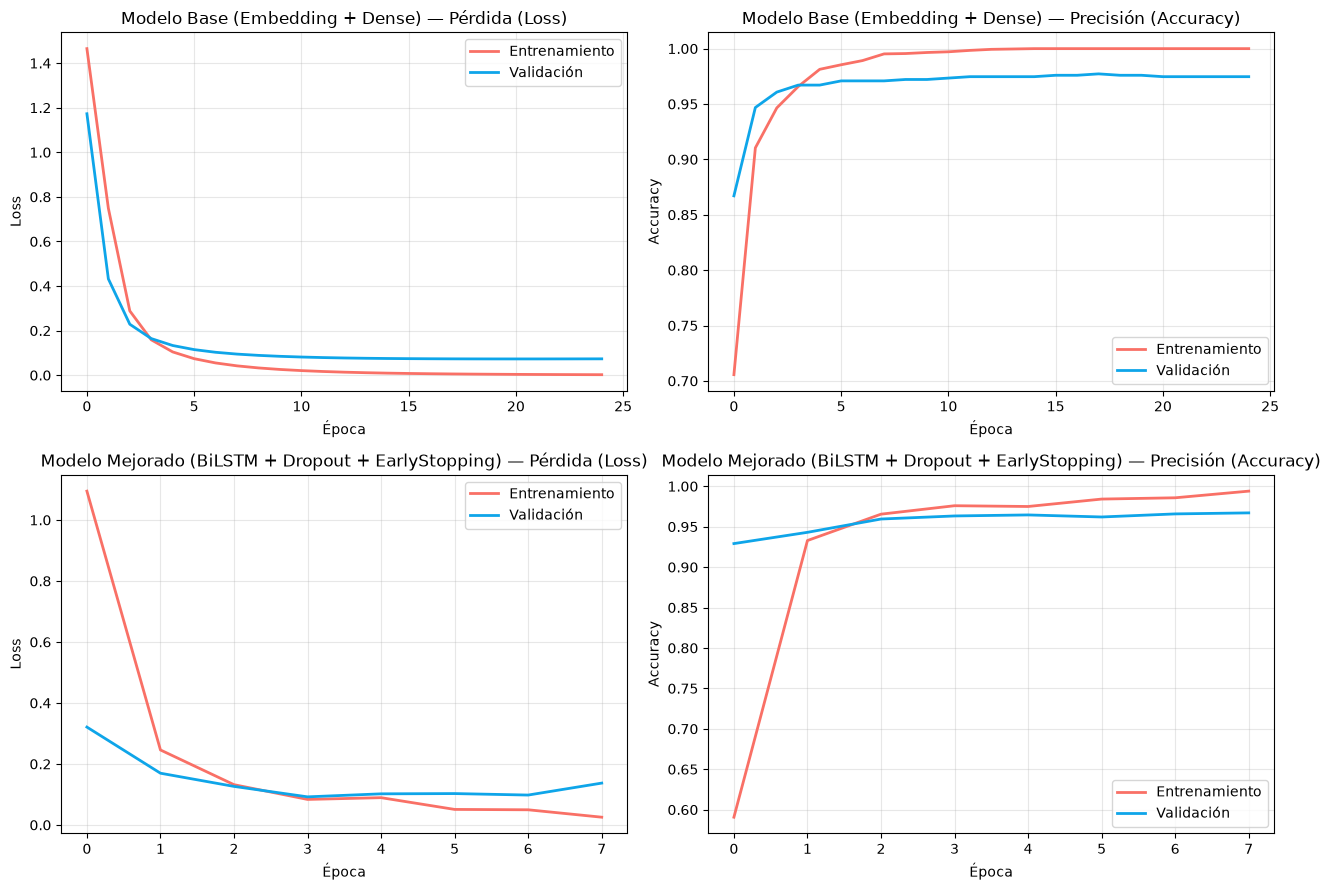

Gráfica guardada en: D:\Documentos\GitHub\Taller-IA\assets\curvas_comparacion_u4.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Fila 1: Modelo Base
axes[0, 0].plot(hist_base.history['loss'], color='#F97066', linewidth=2, label='Entrenamiento')
axes[0, 0].plot(hist_base.history['val_loss'], color='#0EA5E9', linewidth=2, label='Validación')
axes[0, 0].set_title('Modelo Base (Embedding + Dense) — Pérdida (Loss)')
axes[0, 0].set_xlabel('Época'); axes[0, 0].set_ylabel('Loss'); axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(hist_base.history['accuracy'], color='#F97066', linewidth=2, label='Entrenamiento')
axes[0, 1].plot(hist_base.history['val_accuracy'], color='#0EA5E9', linewidth=2, label='Validación')
axes[0, 1].set_title('Modelo Base (Embedding + Dense) — Precisión (Accuracy)')
axes[0, 1].set_xlabel('Época'); axes[0, 1].set_ylabel('Accuracy'); axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)

# Fila 2: Modelo Mejorado
axes[1, 0].plot(hist_mejorado.history['loss'], color='#F97066', linewidth=2, label='Entrenamiento')
axes[1, 0].plot(hist_mejorado.history['val_loss'], color='#0EA5E9', linewidth=2, label='Validación')
axes[1, 0].set_title('Modelo Mejorado (BiLSTM + Dropout + EarlyStopping) — Pérdida (Loss)')
axes[1, 0].set_xlabel('Época'); axes[1, 0].set_ylabel('Loss'); axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(hist_mejorado.history['accuracy'], color='#F97066', linewidth=2, label='Entrenamiento')
axes[1, 1].plot(hist_mejorado.history['val_accuracy'], color='#0EA5E9', linewidth=2, label='Validación')
axes[1, 1].set_title('Modelo Mejorado (BiLSTM + Dropout + EarlyStopping) — Precisión (Accuracy)')
axes[1, 1].set_xlabel('Época'); axes[1, 1].set_ylabel('Accuracy'); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
curvas_path = ASSETS_DIR / 'curvas_comparacion_u4.png'
plt.savefig(curvas_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Gráfica guardada en: {curvas_path}')

>>> Modelo seleccionado para producción: Embedding + GlobalAveragePooling1D + Dense
>>> Test Accuracy: 0.9689 | Test Loss: 0.0851



Reporte de clasificación (conjunto de prueba):
                         precision    recall  f1-score   support

     Fraude y Seguridad     0.9352    0.9625    0.9487       240
 Transferencias y Pagos     0.9746    0.9664    0.9705       238
  Tarjetas y Activación     0.9748    0.9667    0.9707       240
Comisiones y Reembolsos     0.9694    0.9500    0.9596       200
  Cuenta y Verificación     0.9917    0.9958    0.9938       240

               accuracy                         0.9689      1158
              macro avg     0.9691    0.9683    0.9686      1158
           weighted avg     0.9691    0.9689    0.9689      1158



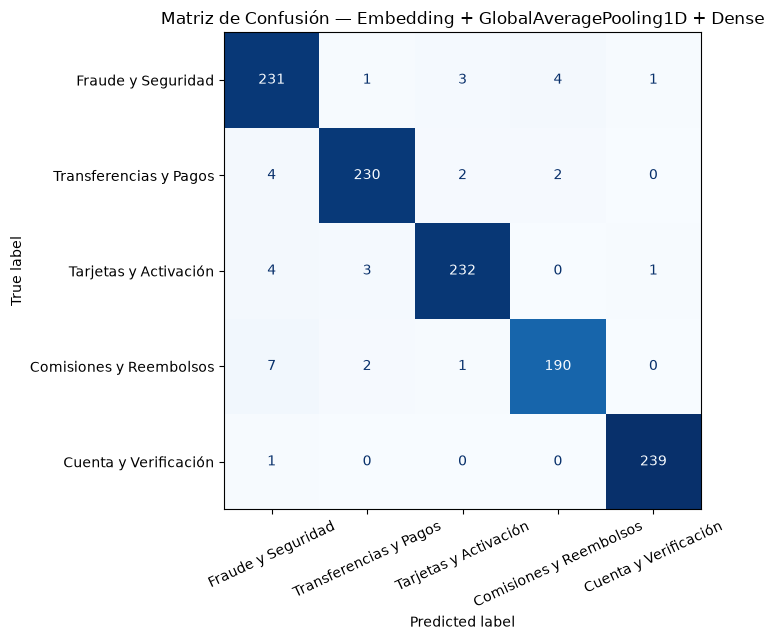

Matriz guardada en: D:\Documentos\GitHub\Taller-IA\assets\matriz_confusion_u4.png


In [7]:
# Seleccionar automáticamente el modelo con mejor accuracy en test
if acc_mej >= acc_base:
    mejor_modelo = modelo_mejorado
    nombre_mejor = 'Embedding + Bidirectional LSTM (con Dropout y EarlyStopping)'
    mejor_acc, mejor_loss = acc_mej, loss_mej
else:
    mejor_modelo = modelo_base
    nombre_mejor = 'Embedding + GlobalAveragePooling1D + Dense'
    mejor_acc, mejor_loss = acc_base, loss_base

print(f'>>> Modelo seleccionado para producción: {nombre_mejor}')
print(f'>>> Test Accuracy: {mejor_acc:.4f} | Test Loss: {mejor_loss:.4f}\n')

probs_test = mejor_modelo.predict(X_test, verbose=0)
y_pred = np.argmax(probs_test, axis=1)

print('Reporte de clasificación (conjunto de prueba):')
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=CLASS_NAMES, cmap='Blues', colorbar=False, ax=ax, xticks_rotation=25
)
ax.set_title(f'Matriz de Confusión — {nombre_mejor}')
plt.tight_layout()
cm_path = ASSETS_DIR / 'matriz_confusion_u4.png'
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Matriz guardada en: {cm_path}')

## 5. Análisis de un Fallo Real (Error Analysis)

Identificamos casos reales del conjunto de prueba donde el modelo falla (preferiblemente con baja confianza `< 0.65` para evidenciar además cómo la regla de gobernanza de `@tool #2` detecta la incertidumbre y ordena escalamiento a Nivel 2).

In [8]:
errores = []
for i in range(len(y_test)):
    if y_pred[i] != y_test[i]:
        conf = float(probs_test[i, y_pred[i]])
        errores.append({
            'test_index': int(i),
            'orig_id': df_test.iloc[i]['orig_id'],
            'text': df_test.iloc[i]['text'],
            'intent_original': df_test.iloc[i]['intent_original'],
            'true_label': CLASS_NAMES[int(y_test[i])],
            'predicted_label': CLASS_NAMES[int(y_pred[i])],
            'confidence': round(conf, 4),
            'prob_true_label': round(float(probs_test[i, y_test[i]]), 4),
        })

# Ordenar por menor confianza para destacar un fallo genuinamente ambiguo
errores_ordenados = sorted(errores, key=lambda e: e['confidence'])
caso_fallo = errores_ordenados[0]

print(f'Total de fallos en conjunto de prueba: {len(errores)} / {len(y_test)} ({len(errores)/len(y_test)*100:.2f}%)')
print('\n=== CASO DE FALLO REAL SELECCIONADO (ERROR ANALYSIS) ===')
print(f"Identificador (orig_id): {caso_fallo['orig_id']} (índice test: {caso_fallo['test_index']})")
print(f"Texto del ticket:        {caso_fallo['text']}")
print(f"Intención Banking77:     {caso_fallo['intent_original']}")
print(f"Valor real:              {caso_fallo['true_label']}")
print(f"Predicción del modelo:   {caso_fallo['predicted_label']}")
print(f"Probabilidad predicha:   {caso_fallo['confidence']:.4f} ({caso_fallo['confidence']*100:.2f}%)")
print(f"Prob. de la clase real:  {caso_fallo['prob_true_label']:.4f} ({caso_fallo['prob_true_label']*100:.2f}%)")

Total de fallos en conjunto de prueba: 36 / 1158 (3.11%)

=== CASO DE FALLO REAL SELECCIONADO (ERROR ANALYSIS) ===
Identificador (orig_id): test_1663 (índice test: 625)
Texto del ticket:        Can I still use the app if I switched phones?
Intención Banking77:     lost_or_stolen_phone
Valor real:              Fraude y Seguridad
Predicción del modelo:   Cuenta y Verificación
Probabilidad predicha:   0.4558 (45.58%)
Prob. de la clase real:  0.3409 (34.09%)


## 6. Exportación de Pesos (`.keras`) y Metadatos (`metadata_u4.json`)

In [9]:
model_path = MODELS_DIR / 'modelo_triaje_u4.keras'
mejor_modelo.save(model_path)

metadatos = {
    'dataset': 'mteb/banking77 (30 intenciones agrupadas en 5 colas PQRS)',
    'class_names': CLASS_NAMES,
    'max_len': MAX_LEN,
    'vocab_size': VOCAB_SIZE,
    'embedding_dim': EMBEDDING_DIM,
    'word_to_index': word_to_index,
    'best_model_name': nombre_mejor,
    'best_test_accuracy': round(float(mejor_acc), 4),
    'best_test_loss': round(float(mejor_loss), 4),
    'base_test_accuracy': round(float(acc_base), 4),
    'base_test_loss': round(float(loss_base), 4),
    'improved_test_accuracy': round(float(acc_mej), 4),
    'improved_test_loss': round(float(loss_mej), 4),
    'error_analysis_case': caso_fallo,
}

meta_path = MODELS_DIR / 'metadata_u4.json'
with meta_path.open('w', encoding='utf-8') as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

tamano_mb = model_path.stat().st_size / (1024 * 1024)
print(f'Modelo guardado en: {model_path} ({tamano_mb:.2f} MB)')
print(f'Metadatos guardados en: {meta_path}')

Modelo guardado en: D:\Documentos\GitHub\Taller-IA\models\modelo_triaje_u4.keras (0.93 MB)
Metadatos guardados en: D:\Documentos\GitHub\Taller-IA\models\metadata_u4.json
